# Bassez et al. 2021 — Breast Cancer
## 03 · Signatures — module geography & Gate 2

Score Gast/pSom/Crest on the malignant-epithelial manifold (union control pool) and read the geography. **Gate 2**: is the embryonic module pattern present? Here Gast and pSom are organised in **cross-repression** (r ≈ −0.5) and Crest is an inverse terminal gradient (pSom↔Crest ≈ −0.9), with **no Gast+pSom co-expression hub diverging into two arms** → the **non-branching** case: GO, with no bifurcation (Gate 3 = NA). Deliverable panels show **raw** per-cell scores.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
print('cells:', adata.shape[0], '| scores present:', [m for m in ['Gast','pSom','Crest'] if m in adata.obs])
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 13834 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 76/81 genes present
pSom: 90/98 genes present
Crest: 104/104 genes present


### Module geography and the Gate-2 call
Gast/pSom cross-repress and both oppose Crest; pseudotime rises Gast/pSom (root) → Crest (terminus). Joint pSom&Crest enrichment < 1 means Crest is an inverse terminal gradient, not a co-expressed hub → single cross-repressive axis, non-branching. **Flag** if Crest enriches the Gast arm (inversion).

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print('  %s vs %s: r = %+.2f' % (a,b, np.corrcoef(adata.obs[a],adata.obs[b])[0,1]))
print('raw module means (global strength):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print('  %s: rho = %+.3f' % (s,rho))
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print('Neural-crest-high decile mean pseudotime = %.2f (terminal if ~1)' % tn[hi.values].mean())
z = lambda x:(x-x.mean())/x.std()
pzs, czs = z(adata.obs['pSom']), z(adata.obs['Crest'])
joint = ((pzs>0.5)&(czs>0.5)).mean(); exp = (pzs>0.5).mean()*(czs>0.5).mean()
print('joint pSom&Crest-high enrichment = %.2f (<1 = inverse gradient, not a co-expressed hub)' % (joint/exp))
gzs = z(adata.obs['Gast']); jointGC = ((gzs>0.5)&(czs>0.5)).mean(); expGC=(gzs>0.5).mean()*(czs>0.5).mean()
print('joint Gast&Crest-high enrichment = %.2f (Crest-on-Gast-arm inversion flag if >1)' % (jointGC/expGC))
print('GATE 2: cross-repressive (Gast/pSom) axis + inverse terminal Crest, no diverging hub -> GO (non-branching)')
print('GATE 3: no bifurcation -> NA')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.70
  Crest_sm vs Gast_sm: r = +0.55
  Crest_sm vs pSom_sm: r = -0.91
raw module means (global strength): {'Gast': -0.0267, 'pSom': 0.0298, 'Crest': -0.0105}
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = +0.161
  pSom_sm: rho = -0.339
  Crest_sm: rho = +0.443
Neural-crest-high decile mean pseudotime = 0.82 (terminal if ~1)
joint pSom&Crest-high enrichment = 0.25 (<1 = inverse gradient, not a co-expressed hub)
joint Gast&Crest-high enrichment = 0.57 (Crest-on-Gast-arm inversion flag if >1)
GATE 2: cross-repressive (Gast/pSom) axis + inverse terminal Crest, no diverging hub -> GO (non-branching)
GATE 3: no bifurcation -> NA


### Signature UMAPs — raw per-cell scores (deliverable)
House style (3.5,1.5), plasma, house orientation; external colorbars. **Raw** scores shown (smoothing aided the analysis but the panels show the honest per-cell readout).

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


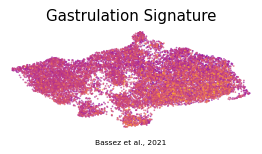

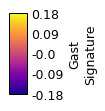

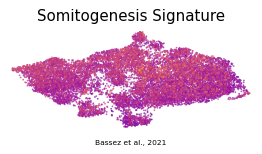

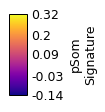

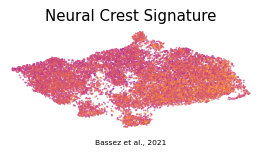

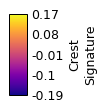

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=8, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hivl = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hivl, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')
    plt.show()

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (13834, 21081)
